# s3 — predicting multi-skip collapse from single skips

**Question:** if we know the accuracy damage of skipping block *a* alone, and block *b* alone, can we predict the damage of skipping both — as one contiguous 2-block span, or as two disjoint single-block skips?

**Why additivity matters:** a global metric (e.g. cosine similarity of the final embeddings) *can* score a multi-block approximation directly, but only by building it and running the model through every translator in it. The point here is to predict combinations **without running them**: every predictor below uses only information gathered from single-block approximations (plus the unmodified model's hidden states), so the cost stays linear in depth instead of growing with the number of combinations.

Predictors of multi-skip damage:

- **naive** — sum of single-skip drops, no fitting: `predicted = drop(a) + drop(b)`
- **angdist** — naive sum + learned terms in the angular distance of the two single-block approximations `a` and `b`, fit per (model, dataset)
- **global_cos** — the same form with the global cosine distance `1 - cosine_sim` of `a` and `b` (from the s2 output-level eval). The global cosine of the 2-block approximation itself is deliberately not used: it would mean running the combination.
- **angdist_span** — *contiguous only*: naive sum + a learned term in the angular distance of the 2-block span `(s, s+2)` itself. Unlike global cosine, this needs no run of the combination: it comes from the same unmodified-model pass as the single spans.

angdist and global_cos share one functional form in both shapes, `delta = b0 + b1 m(a) + b2 m(b) + b3 [drop(a) + drop(b)]`, so they differ only in the metric.

Each is scored by **Pearson r** (does it track the *magnitude* of damage?) and **Spearman rank r** (does it correctly *rank* skips from safest to most damaging?), against the actual measured multi-skip damage. Checked separately for **contiguous** (2-block spans) and **disjoint** (two separate single-block skips) shapes, then we stratify the disjoint case by the gap between the two skips.

Inputs:

- `accuracies/combined/accuracies_results_*_contiguous.csv` — contiguous 2-block spans (from the s2 sweep)
- `accuracies/combined/accuracies_results_*_disjoint.csv` — disjoint pairs (the s3 sweep, ImageNet-1k only)
- `analysis/cka_angular_1_2_layer_spans.csv` — angular distance and accuracy for every 1- and 2-layer span (the single-skip drops come from its 1-layer rows)
- `../4_1-4_2_choosing_blocks/natural/analysis/output_level_eval_s2_*.csv` — global cosine similarity of every single-block approximation
- `../4_1-4_2_choosing_blocks/natural/accuracies/accuracies_results_*.csv` — only for the unskipped baseline accuracy

Spans are written as in the configs: `(s, e)` bridges hidden state `s` to hidden state `e`, so `(s, s+1)` skips one block and `(s, s+2)` skips two. A contiguous span `(s, s+2)` is the union of the single skips `(s, s+1)` and `(s+1, s+2)`.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

S3 = Path.cwd().resolve()
if S3.name == "analysis":
    S3 = S3.parent
S2 = S3.parent / "4_1-4_2_choosing_blocks" / "natural"
ANALYSIS, FIG_DIR = S3 / "analysis", S3 / "figures"
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

MODELS = {"deitsmall": "DeiT-S", "vitsmall": "ViT-S", "dinov2base": "DINOv2-B", "vitlarge": "ViT-L"}
DATASETS = {"cifar100": "CIFAR-100", "imagenet1k": "ImageNet-1k"}
PREDICTORS = ["naive", "angdist", "global_cos", "angdist_span"]

## Load

`span_metrics` is the per-span table of angular distance and accuracy for every 1- and 2-layer span; its 1-layer rows give the single-skip drops. `contiguous_acc` / `disjoint_acc` are the combined 2-block sweeps. From s2 we read the unskipped baseline accuracy and the global cosine similarity of each span's approximation (`COS`); only its single-block entries are used.

In [2]:
def parse_spans(approx_layer):
    return tuple(tuple(s) for s in ast.literal_eval(approx_layer))


# Angular distance (and accuracy) for every 1- and 2-layer span
span_metrics = pd.read_csv(ANALYSIS / "cka_angular_1_2_layer_spans.csv")
span_metrics["span_t"] = list(zip(span_metrics["start"], span_metrics["end"]))
span_key = list(zip(span_metrics["model"], span_metrics["dataset"], span_metrics["span_t"]))
ANG = dict(zip(span_key, span_metrics["angular_dist"]))

# The unskipped baseline is the one number not in the s3 folder
baselines = {}
for model in MODELS:
    for tag in DATASETS:
        acc = pd.read_csv(S2 / "accuracies" / f"accuracies_results_{model}_{tag}.csv")
        baselines[(model, tag)] = acc.loc[acc["approx_layer"] == "[]", "accuracy_mean"].iloc[0]

# Global cosine similarity of the final [CLS] embeddings, from actually running each contiguous
# span's approximation (s2 output-level eval). skip_from/skip_to use the same (s, e) labels as the configs.
COS = {}
for model in MODELS:
    for tag in DATASETS:
        ev = pd.read_csv(S2 / "analysis" / f"output_level_eval_s2_{model}_{tag}.csv")
        COS.update({(model, tag, (s, e)): c for s, e, c in zip(ev["skip_from"], ev["skip_to"], ev["cosine_sim"])})


def load_combined(shape):
    frames = []
    for model in MODELS:
        for tag in DATASETS:
            path = S3 / "accuracies" / "combined" / f"accuracies_results_{model}_{tag}_{shape}.csv"
            if path.exists():
                acc = pd.read_csv(path)[["approx_layer", "accuracy_mean", "accuracy_std"]]
                frames.append(acc.assign(model=model, dataset=tag))
    out = pd.concat(frames, ignore_index=True)
    out["spans"] = out["approx_layer"].map(parse_spans)
    return out


contiguous_acc = load_combined("contiguous")
disjoint_acc = load_combined("disjoint")

single_acc = span_metrics[span_metrics["width"] == 1].rename(columns={"true_accuracy": "accuracy_mean"})
single_acc = single_acc.assign(spans=single_acc["span_t"].map(lambda sp: (sp,)),
                               approx_layer=single_acc["span_t"].map(lambda sp: str([sp])))

for frame in (single_acc, contiguous_acc, disjoint_acc):
    frame["delta_acc"] = [baselines[(m, d)] - a for m, d, a in zip(frame["model"], frame["dataset"], frame["accuracy_mean"])]

single_drop = {(m, d, sp[0]): x for m, d, sp, x in zip(single_acc["model"], single_acc["dataset"], single_acc["spans"], single_acc["delta_acc"])}

pd.DataFrame({
    "baseline_acc": pd.Series(baselines),
    "single": single_acc.groupby(["model", "dataset"]).size(),
    "contiguous": contiguous_acc.groupby(["model", "dataset"]).size(),
    "disjoint": disjoint_acc.groupby(["model", "dataset"]).size(),
}).fillna(0).astype({"single": int, "contiguous": int, "disjoint": int})

baseline_acc  single  contiguous  disjoint
deitsmall  cifar100           0.712      11          10         0
           imagenet1k         0.738      11          10        45
dinov2base cifar100           0.870      11          10         0
           imagenet1k         0.748      11          10        45
vitlarge   cifar100           0.858      23          22         0
           imagenet1k         0.786      23          22       231
vitsmall   cifar100           0.819      11          10         0
           imagenet1k         0.736      11          10        45

In [3]:
single_acc.head(3)

,model,dataset,span,start,end,width,local_cka,cka_embed,angular_dist,accuracy_mean,span_t,spans,approx_layer,delta_acc
0,deitsmall,cifar100,"(0,1)",0,1,1,0.842,0.205,0.229,0.620,"(0, 1)","((0, 1),)","[(0, 1)]",0.093
1,deitsmall,cifar100,"(1,2)",1,2,1,0.891,0.313,0.221,0.643,"(1, 2)","((1, 2),)","[(1, 2)]",0.070
2,deitsmall,cifar100,"(2,3)",2,3,1,0.791,0.404,0.182,0.698,"(2, 3)","((2, 3),)","[(2, 3)]",0.015


In [4]:
contiguous_acc.head(3)

,approx_layer,accuracy_mean,accuracy_std,model,dataset,spans,delta_acc
0,"[(0, 2)]",0.485,0.003,deitsmall,cifar100,"((0, 2),)",0.228
1,"[(1, 3)]",0.619,0.000,deitsmall,cifar100,"((1, 3),)",0.093
2,"[(2, 4)]",0.668,0.002,deitsmall,cifar100,"((2, 4),)",0.045


In [5]:
disjoint_acc.head(3)

,approx_layer,accuracy_mean,accuracy_std,model,dataset,spans,delta_acc
0,"[(0, 1), (2, 3)]",0.587,0.003,deitsmall,imagenet1k,"((0, 1), (2, 3))",0.151
1,"[(1, 2), (3, 4)]",0.668,0.002,deitsmall,imagenet1k,"((1, 2), (3, 4))",0.070
2,"[(2, 3), (4, 5)]",0.698,0.004,deitsmall,imagenet1k,"((2, 3), (4, 5))",0.040


In [6]:

for model in MODELS:
    for dataset in DATASETS:
        df = contiguous_acc[(contiguous_acc["model"] == model) & (contiguous_acc["dataset"] == dataset)]
        true_delta_accs = []
        naive_delta_accs = []
        for i in range(0, 9):
                end = i + 2
                span = (i, end)
                df_row = df[df["spans"].map(lambda sp: sp == (span,))]
                if not df_row.empty:
                    ang = ANG[(model, dataset, span)]
                    delta_acc = df_row["delta_acc"].iloc[0]
                first_skip = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset) & (single_acc["start"] == i)]
                second_skip = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset) & (single_acc["start"] == i+1)]
                first_skip_delta_acc = first_skip["delta_acc"].iloc[0] if not first_skip.empty else np.nan
                second_skip_delta_acc = second_skip["delta_acc"].iloc[0] if not second_skip.empty else np.nan
                naive_delta_acc = first_skip_delta_acc + second_skip_delta_acc
                true_delta_acc = delta_acc
                naive_delta_accs.append(naive_delta_acc)
                true_delta_accs.append(true_delta_acc)
        spearman = spearmanr(naive_delta_accs, true_delta_accs)
        pearson = pearsonr(naive_delta_accs, true_delta_accs)
        
        print(f"{MODELS[model]} {DATASETS[dataset]}: Spearman correlation between naive and true delta_accs: {spearman.correlation:.3f} (p={spearman.pvalue:.3f})")
        print(f"{MODELS[model]} {DATASETS[dataset]}: Pearson correlation between naive and true delta_accs: {pearson.correlation:.3f} (p={pearson.pvalue:.3f})")

DeiT-S CIFAR-100: Spearman correlation between naive and true delta_accs: 1.000 (p=0.000)
DeiT-S CIFAR-100: Pearson correlation between naive and true delta_accs: 0.988 (p=0.000)
DeiT-S ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.950 (p=0.000)
DeiT-S ImageNet-1k: Pearson correlation between naive and true delta_accs: 0.970 (p=0.000)
ViT-S CIFAR-100: Spearman correlation between naive and true delta_accs: 0.983 (p=0.000)
ViT-S CIFAR-100: Pearson correlation between naive and true delta_accs: 0.847 (p=0.004)
ViT-S ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.900 (p=0.001)
ViT-S ImageNet-1k: Pearson correlation between naive and true delta_accs: 0.892 (p=0.001)
DINOv2-B CIFAR-100: Spearman correlation between naive and true delta_accs: 0.900 (p=0.001)
DINOv2-B CIFAR-100: Pearson correlation between naive and true delta_accs: 0.784 (p=0.012)
DINOv2-B ImageNet-1k: Spearman correlation between naive and true delta_accs: 0.700 (p=0.036)
DIN

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

contiguous_results = pd.DataFrame(columns=["model", "dataset", "metric", "n", "spearman_corr", "spearman_pval", "pearson_corr", "pearson_pval"])
for model in MODELS:
    for dataset in DATASETS:
        df = contiguous_acc[(contiguous_acc["model"] == model) & (contiguous_acc["dataset"] == dataset)].copy()
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["start"] = df["spans"].map(lambda sp: sp[0][0])
        df["naive"] = df["start"].map(single_delta) + (df["start"] + 1).map(single_delta)
        # each metric on the two single-block approximations (s, s+1) and (s+1, s+2)
        df["ang1"] = [ANG[(model, dataset, (s, s + 1))] for s in df["start"]]
        df["ang2"] = [ANG[(model, dataset, (s + 1, s + 2))] for s in df["start"]]
        # global cosine of (s, s+2) itself is never used: it would mean running the combination
        df["cos1"] = [1 - COS[(model, dataset, (s, s + 1))] for s in df["start"]]
        df["cos2"] = [1 - COS[(model, dataset, (s + 1, s + 2))] for s in df["start"]]
        # angular distance of the 2-block span itself: free, from the same unmodified-model pass as the single spans
        df["ang_span"] = [ANG[(model, dataset, sp[0])] for sp in df["spans"]]
        df = df.dropna(subset=["naive"])

        # naive: no fitting. angdist / global_cos: OLS delta_acc ~ intercept + metric(a) + metric(b) + naive, the same
        # form as the disjoint case. angdist_span: OLS delta_acc ~ intercept + ang(s, s+2) + naive. All scored on leave-one-out predictions.
        predictions = {"naive": df["naive"]}
        for metric, name in [("ang", "angdist"), ("cos", "global_cos")]:
            predictions[name] = cross_val_predict(LinearRegression(), df[[f"{metric}1", f"{metric}2", "naive"]], df["delta_acc"], cv=LeaveOneOut())
        predictions["angdist_span"] = cross_val_predict(LinearRegression(), df[["ang_span", "naive"]], df["delta_acc"], cv=LeaveOneOut())

        for name, pred in predictions.items():
            spearman = spearmanr(pred, df["delta_acc"])
            pearson = pearsonr(pred, df["delta_acc"])
            print(f"{MODELS[model]} {DATASETS[dataset]} [{name}]: "
                  f"Spearman {spearman.statistic:.3f} (p={spearman.pvalue:.3f}), "
                  f"Pearson {pearson.statistic:.3f} (p={pearson.pvalue:.3f})")
            contiguous_results_row = {
                "model": model,
                "dataset": dataset,
                "metric": name,
                "n": len(df),
                "spearman_corr": spearman.statistic,
                "spearman_pval": spearman.pvalue,
                "pearson_corr": pearson.statistic,
                "pearson_pval": pearson.pvalue
            }
            contiguous_results = pd.concat([contiguous_results, pd.DataFrame([contiguous_results_row])], ignore_index=True)


DeiT-S CIFAR-100 [naive]: Spearman 1.000 (p=0.000), Pearson 0.989 (p=0.000)
DeiT-S CIFAR-100 [angdist]: Spearman 0.915 (p=0.000), Pearson 0.940 (p=0.000)
DeiT-S CIFAR-100 [global_cos]: Spearman 0.988 (p=0.000), Pearson 0.971 (p=0.000)
DeiT-S CIFAR-100 [angdist_span]: Spearman 1.000 (p=0.000), Pearson 0.953 (p=0.000)
DeiT-S ImageNet-1k [naive]: Spearman 0.964 (p=0.000), Pearson 0.969 (p=0.000)
DeiT-S ImageNet-1k [angdist]: Spearman 0.976 (p=0.000), Pearson 0.952 (p=0.000)
DeiT-S ImageNet-1k [global_cos]: Spearman 0.964 (p=0.000), Pearson 0.936 (p=0.000)
DeiT-S ImageNet-1k [angdist_span]: Spearman 0.976 (p=0.000), Pearson 0.914 (p=0.000)
ViT-S CIFAR-100 [naive]: Spearman 0.988 (p=0.000), Pearson 0.854 (p=0.002)
ViT-S CIFAR-100 [angdist]: Spearman 0.842 (p=0.002), Pearson 0.764 (p=0.010)
ViT-S CIFAR-100 [global_cos]: Spearman 0.697 (p=0.025), Pearson 0.450 (p=0.191)
ViT-S CIFAR-100 [angdist_span]: Spearman 0.915 (p=0.000), Pearson 0.687 (p=0.028)
ViT-S ImageNet-1k [naive]: Spearman 0.927 

/var/folders/qw/dj7vjbyd6kb8q83q6chjb9m00000gn/T/ipykernel_72902/2564171164.py:45: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  contiguous_results = pd.concat([contiguous_results, pd.DataFrame([contiguous_results_row])], ignore_index=True)


ViT-L CIFAR-100 [naive]: Spearman 0.955 (p=0.000), Pearson 0.817 (p=0.000)
ViT-L CIFAR-100 [angdist]: Spearman 0.275 (p=0.215), Pearson 0.584 (p=0.004)
ViT-L CIFAR-100 [global_cos]: Spearman 0.330 (p=0.133), Pearson 0.027 (p=0.904)
ViT-L CIFAR-100 [angdist_span]: Spearman 0.451 (p=0.035), Pearson 0.590 (p=0.004)
ViT-L ImageNet-1k [naive]: Spearman 0.802 (p=0.000), Pearson 0.864 (p=0.000)
ViT-L ImageNet-1k [angdist]: Spearman 0.670 (p=0.001), Pearson 0.677 (p=0.001)
ViT-L ImageNet-1k [global_cos]: Spearman -0.039 (p=0.863), Pearson 0.247 (p=0.269)
ViT-L ImageNet-1k [angdist_span]: Spearman 0.552 (p=0.008), Pearson 0.679 (p=0.001)


In [8]:
contiguous_results.groupby(["metric"]).agg({"spearman_corr": ["median", "std"], "pearson_corr": ["median", "std"]})

spearman_corr       pearson_corr      
                    median   std       median   std
metric                                             
angdist              0.756 0.284        0.721 0.289
angdist_span         0.818 0.224        0.683 0.269
global_cos           0.776 0.393        0.685 0.398
naive                0.941 0.088        0.860 0.069

Naive summation is the strongest median predictor for contiguous spans (Pearson 0.86, Spearman 0.94). The leave-one-out corrections are all worse on median: angdist 0.72 / 0.76, global_cos 0.69 / 0.78, angdist_span 0.68 / 0.82 (Pearson / Spearman). With only 10 spans per 12-block combo (22 for ViT-L) the extra regressors overfit more than they correct. global_cos has the largest spread: it edges naive on DeiT-S, DINOv2-B/CIFAR-100 and ViT-S/ImageNet-1k, but collapses on ViT-L (Pearson 0.03 / 0.25) and DINOv2-B/ImageNet-1k (0.23). Giving angdist the 2-block span instead of the two single spans changes little (median Pearson 0.68 vs 0.72), so the comparison with global_cos is not decided by which angular-distance terms it gets.

In [9]:
contiguous_results.pivot_table(index=["model", "dataset"], columns="metric", values=["pearson_corr", "spearman_corr"]).round(3)

pearson_corr                                \
metric                     angdist angdist_span global_cos naive   
model      dataset                                                 
deitsmall  cifar100          0.940        0.953      0.971 0.989   
           imagenet1k        0.952        0.914      0.936 0.969   
dinov2base cifar100          0.121        0.159      0.920 0.796   
           imagenet1k        0.375        0.410      0.227 0.855   
vitlarge   cifar100          0.584        0.590      0.027 0.817   
           imagenet1k        0.677        0.679      0.247 0.864   
vitsmall   cifar100          0.764        0.687      0.450 0.854   
           imagenet1k        0.841        0.855      0.975 0.909   

                      spearman_corr                                
metric                      angdist angdist_span global_cos naive  
model      dataset                                                 
deitsmall  cifar100           0.915        1.000      0.988 1.000  
           imagenet1k         0.976        0.976      0.964 0.964  
dinov2base cifar100           0.261        0.806      0.855 0.915  
           imagenet1k         0.503        0.479      0.248 0.758  
vitlarge   cifar100           0.275        0.451      0.330 0.955  
           imagenet1k         0.670        0.552     -0.039 0.802  
vitsmall   cifar100           0.842        0.915      0.697 0.988  
           imagenet1k         0.842        0.830      0.952 0.927

## 2. Disjoint — two separate single-block skips, e.g. `[(0, 1), (2, 3)]`

ImageNet-1k only (the s3 sweep), all 4 backbones. Same naive / angdist / global_cos predictors (no angdist_span: a disjoint pair has no single span), same two correlations. The disjoint regression keeps the two similarity values **separate** (`metric_1`, `metric_2`) rather than summing them, since the two skips are distinct bridges and summing would throw away which one is more responsible for the damage.

The **gap** between the skips is `s2 - s1` (the distance between the two dropped blocks), so `[(0, 1), (2, 3)]` has gap 2: one untouched block in between.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict

disjoint_results = pd.DataFrame(columns=["model", "dataset", "metric", "n", "spearman_corr", "spearman_pval", "pearson_corr", "pearson_pval"])
for model in MODELS:
    for dataset in DATASETS:
        df = disjoint_acc[(disjoint_acc["model"] == model) & (disjoint_acc["dataset"] == dataset)].copy()
        if df.empty:
            continue
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["skip1"] = df["spans"].map(lambda sp: sorted(sp)[0])
        df["skip2"] = df["spans"].map(lambda sp: sorted(sp)[1])
        df["naive"] = df["skip1"].map(lambda sp: single_delta.get(sp[0])) + df["skip2"].map(lambda sp: single_delta.get(sp[0]))
        df["ang1"] = [ANG[(model, dataset, sp)] for sp in df["skip1"]]
        df["ang2"] = [ANG[(model, dataset, sp)] for sp in df["skip2"]]
        df["cos1"] = [1 - COS[(model, dataset, sp)] for sp in df["skip1"]]
        df["cos2"] = [1 - COS[(model, dataset, sp)] for sp in df["skip2"]]
        df = df.dropna(subset=["naive"])

        # naive: no fitting. angdist / global_cos: OLS delta_acc ~ intercept + metric(skip 1) + metric(skip 2) + naive, scored on leave-one-out predictions
        predictions = {"naive": df["naive"]}
        for metric, name in [("ang", "angdist"), ("cos", "global_cos")]:
            X = df[[f"{metric}1", f"{metric}2", "naive"]]
            predictions[name] = cross_val_predict(LinearRegression(), X, df["delta_acc"], cv=LeaveOneOut())

        for name, pred in predictions.items():
            spearman = spearmanr(pred, df["delta_acc"])
            pearson = pearsonr(pred, df["delta_acc"])
            print(f"{MODELS[model]} {DATASETS[dataset]} [{name}]: "
                  f"Spearman {spearman.statistic:.3f} (p={spearman.pvalue:.3f}), "
                  f"Pearson {pearson.statistic:.3f} (p={pearson.pvalue:.3f})")
            disjoint_results_row = {
                "model": model,
                "dataset": dataset,
                "metric": name,
                "n": len(df),
                "spearman_corr": spearman.statistic,
                "spearman_pval": spearman.pvalue,
                "pearson_corr": pearson.statistic,
                "pearson_pval": pearson.pvalue
            }
            disjoint_results = pd.concat([disjoint_results, pd.DataFrame([disjoint_results_row])], ignore_index=True)

DeiT-S ImageNet-1k [naive]: Spearman 0.954 (p=0.000), Pearson 0.973 (p=0.000)
DeiT-S ImageNet-1k [angdist]: Spearman 0.966 (p=0.000), Pearson 0.983 (p=0.000)
DeiT-S ImageNet-1k [global_cos]: Spearman 0.972 (p=0.000), Pearson 0.977 (p=0.000)
ViT-S ImageNet-1k [naive]: Spearman 0.933 (p=0.000), Pearson 0.940 (p=0.000)
ViT-S ImageNet-1k [angdist]: Spearman 0.964 (p=0.000), Pearson 0.954 (p=0.000)
ViT-S ImageNet-1k [global_cos]: Spearman 0.980 (p=0.000), Pearson 0.973 (p=0.000)
DINOv2-B ImageNet-1k [naive]: Spearman 0.982 (p=0.000), Pearson 0.987 (p=0.000)
DINOv2-B ImageNet-1k [angdist]: Spearman 0.978 (p=0.000), Pearson 0.986 (p=0.000)
DINOv2-B ImageNet-1k [global_cos]: Spearman 0.980 (p=0.000), Pearson 0.982 (p=0.000)


/var/folders/qw/dj7vjbyd6kb8q83q6chjb9m00000gn/T/ipykernel_72902/2336442580.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  disjoint_results = pd.concat([disjoint_results, pd.DataFrame([disjoint_results_row])], ignore_index=True)


ViT-L ImageNet-1k [naive]: Spearman 0.924 (p=0.000), Pearson 0.999 (p=0.000)
ViT-L ImageNet-1k [angdist]: Spearman 0.928 (p=0.000), Pearson 0.999 (p=0.000)
ViT-L ImageNet-1k [global_cos]: Spearman 0.923 (p=0.000), Pearson 0.999 (p=0.000)


In [11]:
disjoint_results.groupby(["metric"]).agg({"spearman_corr": ["median", "std"], "pearson_corr": ["median", "std"]})

spearman_corr       pearson_corr      
                  median   std       median   std
metric                                           
angdist            0.965 0.021        0.984 0.019
global_cos         0.976 0.027        0.980 0.012
naive              0.944 0.026        0.980 0.026

In [12]:
disjoint_results.pivot_table(index=["model", "dataset"], columns="metric", values=["pearson_corr", "spearman_corr"]).round(3)

pearson_corr                  spearman_corr             \
metric                     angdist global_cos naive       angdist global_cos   
model      dataset                                                             
deitsmall  imagenet1k        0.983      0.977 0.973         0.966      0.972   
dinov2base imagenet1k        0.986      0.982 0.987         0.978      0.980   
vitlarge   imagenet1k        0.999      0.999 0.999         0.928      0.923   
vitsmall   imagenet1k        0.954      0.973 0.940         0.964      0.980   

                             
metric                naive  
model      dataset           
deitsmall  imagenet1k 0.954  
dinov2base imagenet1k 0.982  
vitlarge   imagenet1k 0.924  
vitsmall   imagenet1k 0.933

## 3. Stratify the disjoint case by distance between the two skips

Split each model's disjoint spans into three equal-sized bins by gap (near / mid / far — a simple tercile split by rank), then re-check the **naive** additive predictor's Pearson r and R² within each bin.

In [13]:
from sklearn.metrics import r2_score

# Edit these to decide what counts as close: right-inclusive gap edges, gap = start(skip 2) - start(skip 1)
GAP_BINS = [1, 3, 5, np.inf]
GAP_LABELS = ["near (2-3)", "mid (4-5)", "far (6+)"]

gap_rows = []
for model in MODELS:
    for dataset in DATASETS:
        df = disjoint_acc[(disjoint_acc["model"] == model) & (disjoint_acc["dataset"] == dataset)].copy()
        if df.empty:
            continue
        single_delta = single_acc[(single_acc["model"] == model) & (single_acc["dataset"] == dataset)].set_index("start")["delta_acc"]

        df["skip1"] = df["spans"].map(lambda sp: sorted(sp)[0])
        df["skip2"] = df["spans"].map(lambda sp: sorted(sp)[1])
        df["naive"] = df["skip1"].map(lambda sp: single_delta.get(sp[0])) + df["skip2"].map(lambda sp: single_delta.get(sp[0]))
        df["gap"] = df["skip2"].map(lambda sp: sp[0]) - df["skip1"].map(lambda sp: sp[0])
        df["gap_bin"] = pd.cut(df["gap"], bins=GAP_BINS, labels=GAP_LABELS)
        df = df.dropna(subset=["naive"])

        for gap_bin, b in df.groupby("gap_bin", observed=True):
            gap_rows.append({
                "model": MODELS[model], "dataset": DATASETS[dataset], "gap_bin": gap_bin, "n": len(b),
                "r2": r2_score(b["delta_acc"], b["naive"]) if len(b) > 1 else np.nan,
                "pearson": pearsonr(b["naive"], b["delta_acc"]).statistic if len(b) > 2 else np.nan,
                "spearman": spearmanr(b["naive"], b["delta_acc"]).statistic if len(b) > 2 else np.nan,
            })

gap_stratified = pd.DataFrame(gap_rows)
gap_stratified

,model,dataset,gap_bin,n,r2,pearson,spearman
0,DeiT-S,ImageNet-1k,near (2-3),17,0.568,0.973,0.941
1,DeiT-S,ImageNet-1k,mid (4-5),13,0.913,0.992,0.967
2,DeiT-S,ImageNet-1k,far (6+),15,0.990,0.997,0.996
3,ViT-S,ImageNet-1k,near (2-3),17,0.707,0.982,0.980
4,ViT-S,ImageNet-1k,mid (4-5),13,0.541,0.908,0.890
5,ViT-S,ImageNet-1k,far (6+),15,0.905,0.960,0.939
6,DINOv2-B,ImageNet-1k,near (2-3),17,0.936,0.990,0.973
7,DINOv2-B,ImageNet-1k,mid (4-5),13,0.979,0.994,0.989
8,DINOv2-B,ImageNet-1k,far (6+),15,0.992,0.996,0.989
9,ViT-L,ImageNet-1k,near (2-3),41,0.996,0.999,0.864


In [14]:
gap_stratified.groupby(["gap_bin"]).agg({"pearson": ["median", "std"], "spearman": ["median", "std"]})

pearson       spearman      
            median   std   median   std
gap_bin                                
far (6+)     0.997 0.019    0.965 0.031
mid (4-5)    0.993 0.043    0.950 0.043
near (2-3)   0.986 0.011    0.957 0.053

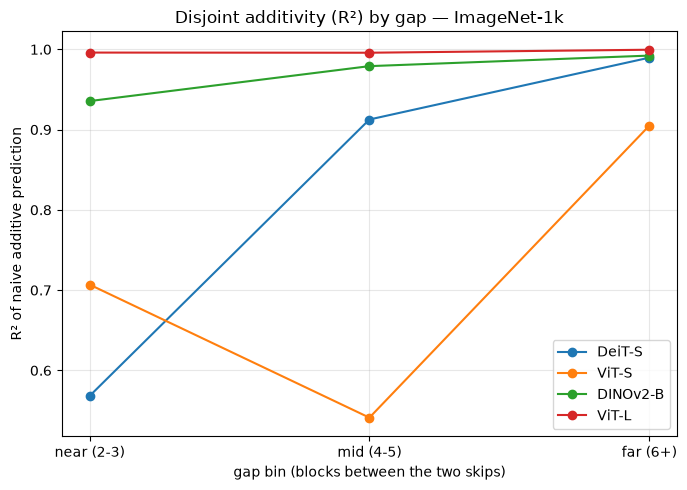

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
for model, g in gap_stratified.groupby("model", sort=False):
    ax.plot(g["gap_bin"].astype(str), g["r2"], marker="o", label=model)
ax.set_title("Disjoint additivity (R²) by gap — ImageNet-1k")
ax.set_xlabel("gap bin (blocks between the two skips)")
ax.set_ylabel("R² of naive additive prediction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "s3_disjoint_gap.png", dpi=200, bbox_inches="tight")
plt.show()

For every backbone R² rises from the near to the far bin: the farther apart the two skipped blocks, the closer naive summation gets to exact. The effect is largest for DeiT-S (0.54 → 0.99) and ViT-S (0.67 → 0.91); ViT-L is near-additive at every gap. Pearson stays high in every bin, so near pairs are still ranked well; what breaks down is the magnitude, i.e. close pairs interact. The tercile bins overlap at their edges (e.g. gap 3 sits in both near and mid for the 12-block models) because the split is by rank.

## 4. Illustrative example — ViT-L / ImageNet-1k

Raw accuracy curves behind the numbers above: single-block skips, contiguous 2-block skips, and disjoint skips with exactly one untouched block between them (gap 2).

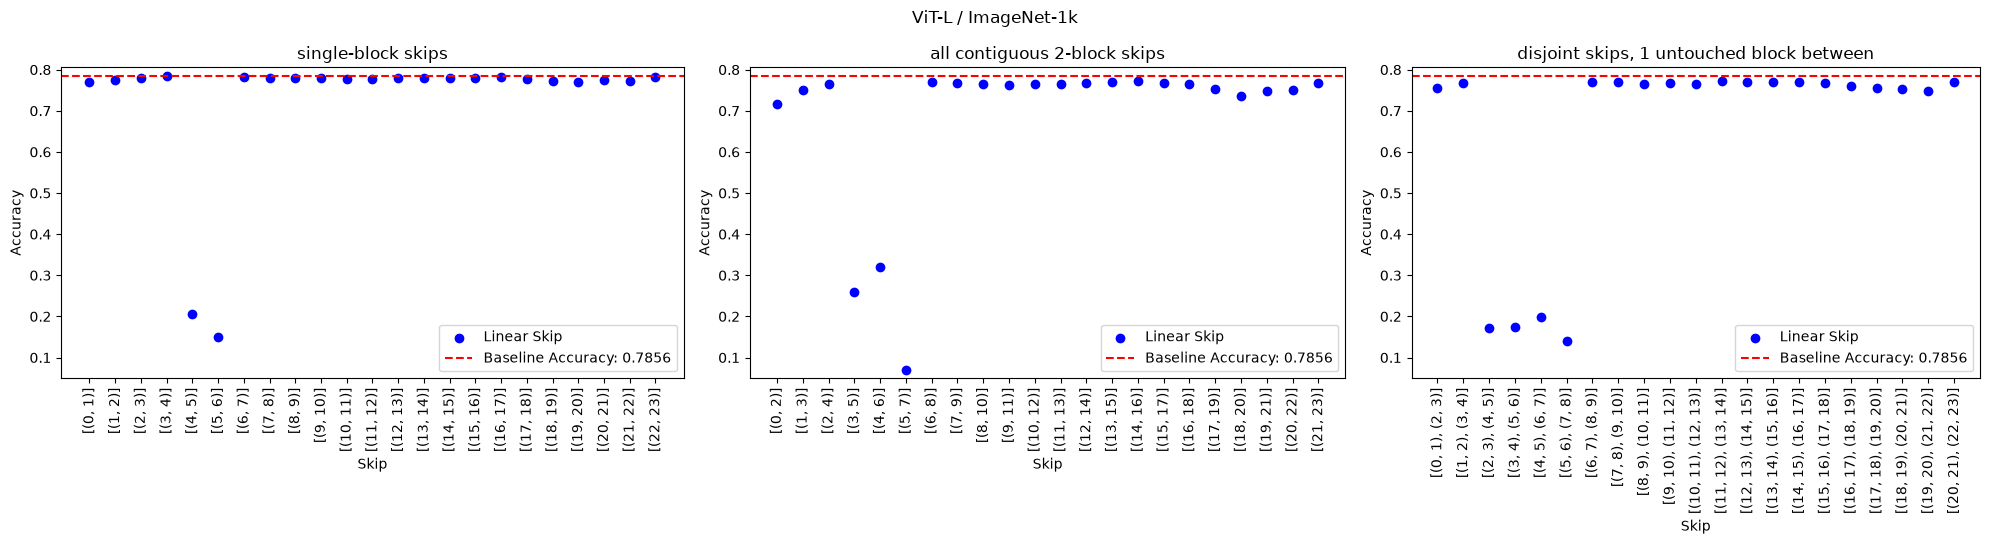

In [16]:
model, dataset = "vitlarge", "imagenet1k"
baseline = baselines[(model, dataset)]


def first_start(spans):
    return min(s for s, _ in spans)


def select(frame, keep=lambda sp: True):
    sel = frame[(frame["model"] == model) & (frame["dataset"] == dataset) & frame["spans"].map(keep)].copy()
    return sel.assign(first=sel["spans"].map(first_start)).sort_values("first")


single = select(single_acc)
contiguous_two = select(contiguous_acc)
gapped = select(disjoint_acc, lambda sp: sorted(sp)[1][0] - sorted(sp)[0][0] == 2)

panels = [
    (single, "single-block skips"),
    (contiguous_two, "all contiguous 2-block skips"),
    (gapped, "disjoint skips, 1 untouched block between"),
]
all_acc = pd.concat([d["accuracy_mean"] for d, _ in panels])
best_val, worst_val = max(all_acc.max(), baseline) + 0.02, all_acc.min() - 0.02

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), width_ratios=[len(d) for d, _ in panels])
fig.suptitle(f"{MODELS[model]} / {DATASETS[dataset]}")

for ax, (data, subtitle) in zip(axes, panels):
    ax.scatter(data["approx_layer"], data["accuracy_mean"], color="blue", label="Linear Skip")
    ax.axhline(y=baseline, color="red", linestyle="--", label=f"Baseline Accuracy: {baseline:.4f}")
    ax.set_title(subtitle)
    ax.set_xlabel("Skip")
    ax.set_ylabel("Accuracy")
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylim(worst_val, best_val)
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "s3_vitlarge_imagenet1k_skips.png", dpi=200, bbox_inches="tight")
plt.show()

## Takeaways

1. **Contiguous 2-block spans (CIFAR-100, ImageNet-1k, 4 backbones)**: naive summation of the two single-skip drops is the most robust predictor; learned angular-distance and single-block global-cosine corrections don't beat it out of sample on median, and global cosine is the least stable. Using the free 2-block angular distance instead of the two single-block values doesn't change this.
2. **Disjoint pairs (ImageNet-1k, 4 backbones)**: naive summation already predicts and ranks well; angdist and global_cos corrections are within noise of it (global_cos has the best median Spearman, 0.98 vs 0.94, driven by ViT-S and DeiT-S).
3. **Stratifying disjoint pairs by gap** shows additivity strengthening with distance for every backbone, i.e. the interaction between skipped blocks decays with separation; this is why disjoint pairs are closer to additive than contiguous spans.

In [17]:
# predictor names as in PREDICTORS
pd.concat([contiguous_results.assign(shape="contiguous"), disjoint_results.assign(shape="disjoint")]) \
    .rename(columns={"metric": "predictor", "pearson_corr": "pearson_r", "spearman_corr": "spearman_r"}) \
    [["model", "dataset", "predictor", "n", "pearson_r", "spearman_r", "shape"]] \
    .to_csv(ANALYSIS / "s3_predictor_comparison.csv", index=False)
gap_stratified.to_csv(ANALYSIS / "s3_disjoint_additivity_by_gap.csv", index=False)